# CHLA-Z methods 2: OOI retrieval, QC and solar-time windows

**Author:** Eli Holmes (NOAA)<br>
Last updated: November 23, 2026

> **What this notebook is.** One of four *data methods* notebooks for the
> CHLA-Z tables in `datasets/chla_z/data/`. It shows, on one instrument and
> one month, exactly how Ocean Observatories Initiative (OOI) chlorophyll
> data are retrieved, quality controlled, binned and corrected. It is **not**
> about model training.
>
> **What it is not.** It does not build the tables. The full build runs from
> `datasets/chla_z/build.py`, which calls the same functions in
> `src/chla_z_build.py` that this notebook calls. The last section checks the
> result against the released table.

| # | Notebook | Method | Build stage |
|---|---|---|---|
| 1 | 01-argo-retrieval-qc | BGC-Argo retrieval, QC, depth bins | `argo` |
| 2 | **02-ooi-retrieval-qc** | OOI retrieval, QC, 3 h solar-time windows, Sauzède correction | `ooi-fetch`, `ooi` |
| 3 | 03-pace-matchups | PACE Rrs, chlor_a, Kd matchups | `pace`, `pace-merge` |
| 4 | 04-olci-matchups | Sentinel-3 OLCI Rrs matchups | `olci`, `olci-merge` |

**The rules, in brief.** OOI fluorometers on moorings and profilers, from the
OOI ERDDAP, 2024-03-01 to 2026-10-31.

1. Keep samples whose aggregate QC flag (`<chl>_qc_agg`) is 1 (pass).
2. Depth is `-z`, or a fixed depth for instruments that publish a wrong `z`;
   keep depths in (0, 200] m.
3. Group samples into 3 h windows of *local mean solar time* (00–03, 03–06,
   … h), not UTC days, and average each window in the same 10 m (A, B] bins
   as Argo.
4. Divide by the Sauzède et al. fluorescence:chla ratio for the site, so OOI
   is on the same footing as Argo `CHLA_ADJUSTED`.

Runs in about a minute; the only download is one instrument-month (~9 MB).

In [1]:
import io
import sys

if "../../../src" not in sys.path:
    sys.path.insert(0, "../../../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import chla_z_build as b
from sauzede_lut import chla_scaling_factor, load_lut

## 1. Which instruments

The instrument list is `OOI_DATASETS` in `src/chla_z_ooi_datasets.py`: ERDDAP
dataset ids and a description of each. Three are left out for reasons that do
not depend on dates. Of the rest, 30 have data in the date range.

In [2]:
from chla_z_ooi_datasets import OOI_DATASETS

print(len(OOI_DATASETS), "listed,", len(b.ooi_datasets()), "used")
b.OOI_EXCLUDE

64 listed, 61 used


{'ooi-ce02shsp-sp002-07-flortj000': 'no qc_agg variable',
 'ooi-rs01sbps-pc01a-4c-flordd103': 'no qc_agg variable',
 'ooi-gp02hypm-wfp03-01-flordl000': '2000 m and deeper'}

Fixed instruments sometimes publish `z = 0` although the sensor sits at a
known depth. These get their depth from `b.DEPTH_OVERRIDE_M` (metres, positive
down). Without it, a sensor at 130 m would fill the surface bin.

In [3]:
pd.Series(b.DEPTH_OVERRIDE_M, name="depth_m").to_frame()

,depth_m
ooi-gi01sumo-rid16-02-flortd000,12.0
ooi-gi03flmb-ris01-05-flortd000,25.0
ooi-gi03flma-ris01-05-flortd000,26.0
ooi-gi01sumo-rii11-02-flordg031,40.0
ooi-gi01sumo-rii11-02-flordg032,80.0
ooi-gi01sumo-rii11-02-flordg033,130.0
ooi-gp03flma-ris01-05-flortd000,28.0
ooi-gp03flmb-ris01-05-flortd000,30.0
ooi-rs03axps-pc03a-4c-flordd303,187.0
ooi-ce04ossm-rid27-02-flortd000,7.0


## 2. Retrieve one instrument-month

We use the Oregon Offshore shallow profiler (Coastal Endurance), July 2025.
`b.ooi_url` builds the ERDDAP tabledap request: time, position, `z`,
chlorophyll and its aggregate QC flag, above 200 m. Moorings and profilers
name the chlorophyll variable differently; `b.ooi_chl_var` picks the right one.

In [4]:
dataset_id = "ooi-ce04osps-sf01b-3a-flortd104"
month = "2025-07"
print(b.ooi_datasets()[dataset_id])
url = b.ooi_url(dataset_id, month)
print(url)

Coastal Endurance: Oregon Offshore Cabled Shallow Profiler Mooring: Shallow Profiler (SF01B): 3-Wavelength Fluorometer
https://erddap.dataexplorer.oceanobservatories.org/erddap/tabledap/ooi-ce04osps-sf01b-3a-flortd104.csv?time%2Clatitude%2Clongitude%2Cz%2Cmass_concentration_of_chlorophyll_a_in_sea_water_profiler_depth_enabled%2Cmass_concentration_of_chlorophyll_a_in_sea_water_profiler_depth_enabled_qc_agg&time%3E=2025-07-01T00:00:00Z&time%3C2025-08-01T00:00:00Z&z%3E=-200


`b._http_get` retries dropped connections and server errors with back-off.
ERDDAP answers 404 both for "no matching results" and for some failures, so
the build only treats a 404 as empty when its body says "no matching
results". The build saves the raw CSV per dataset-month
(`b.ooi_month_unit`); here we keep it in memory.

In [5]:
status, body = b._http_get(url)
raw = pd.read_csv(io.BytesIO(body), skiprows=[1])  # row 1 holds units
print(status, f"{len(body) / 1e6:.1f} MB,", len(raw), "samples")
raw.head()

200 8.8 MB, 140714 samples


,time,latitude,longitude,z,mass_concentration_of_chlorophyll_a_in_sea_water_profiler_depth_enabled,mass_concentration_of_chlorophyll_a_in_sea_water_profiler_depth_enabled_qc_agg
0,2025-07-01T00:00:00Z,44.374227,-124.956461,-194.0,0.043818,1
1,2025-07-01T00:01:00Z,44.374227,-124.956461,-194.0,0.039194,1
2,2025-07-01T00:02:00Z,44.374227,-124.956461,-194.0,0.046900,1
3,2025-07-01T00:03:00Z,44.374227,-124.956461,-194.0,0.058130,1
4,2025-07-01T00:04:00Z,44.374227,-124.956461,-194.0,0.044519,1


## 3. Quality control and depth

`b.ooi_good_samples` applies steps 1 and 2 and adds `solar`, the local mean
solar time of each sample: UTC plus longitude/15 hours.

In [6]:
chl_var = b.ooi_chl_var(dataset_id)
qc = raw[f"{chl_var}_qc_agg"].value_counts().sort_index()
print("qc_agg flags:", qc.to_dict())

good = b.ooi_good_samples(raw.copy(), dataset_id, chl_var)
print(f"{len(good)} of {len(raw)} samples kept")
good.head()

qc_agg flags: {1: 128499, 3: 344, 4: 11871}
128499 of 140714 samples kept


,time,latitude,longitude,depth,CHLA,solar
0,2025-07-01 00:00:00+00:00,44.374227,-124.956461,194.0,0.043818,2025-06-30 15:40:10.449360002+00:00
1,2025-07-01 00:01:00+00:00,44.374227,-124.956461,194.0,0.039194,2025-06-30 15:41:10.449360002+00:00
2,2025-07-01 00:02:00+00:00,44.374227,-124.956461,194.0,0.046900,2025-06-30 15:42:10.449360002+00:00
3,2025-07-01 00:03:00+00:00,44.374227,-124.956461,194.0,0.058130,2025-06-30 15:43:10.449360002+00:00
4,2025-07-01 00:04:00+00:00,44.374227,-124.956461,194.0,0.044519,2025-06-30 15:44:10.449360002+00:00


## 4. Windows of local solar time

Why windows and not days: chlorophyll fluorescence is quenched in bright
light, so the hour of sampling matters. A UTC-day mean put every OOI time
near 12 UTC, which at OOI longitudes is about 3–9 h solar time, nearly the
same for every row of a site. The 3 h windows keep the time of day, and each
row's `time` is the mean UTC time of its samples.

This profiler samples around the clock:

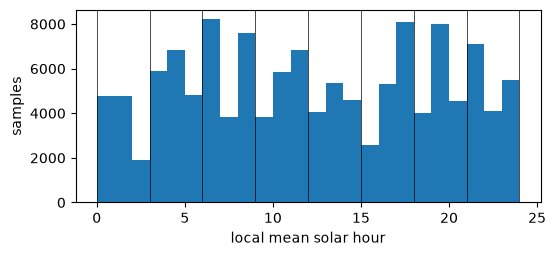

In [7]:
fig, ax = plt.subplots(figsize=(6, 2.5))
ax.hist(good["solar"].dt.hour + good["solar"].dt.minute / 60, bins=np.arange(0, 25, 1))
for h in range(0, 25, b.OOI_WINDOW_H):
    ax.axvline(h, color="k", lw=0.5)
ax.set_xlabel("local mean solar hour")
ax.set_ylabel("samples");

`b.ooi_window_profiles` makes one row per window. `profile_id` is
`<dataset>_<solar date>T<window start hour>`.

In [8]:
win = b.ooi_window_profiles(good, dataset_id, b.ooi_datasets()[dataset_id])
print(len(win), "windows")
win[["profile_id", "time", "lat", "lon", "n_samples", "CHLA_0_10", "CHLA_10_20"]].head(8)

249 windows


,profile_id,time,lat,lon,n_samples,CHLA_0_10,CHLA_10_20
0,ooi-ce04osps-sf01b-3a-flortd104_20250630T15,2025-07-01 01:22:43.841336064+00:00,44.374227,-124.956461,479,3.685431,2.867679
1,ooi-ce04osps-sf01b-3a-flortd104_20250630T18,2025-07-01 03:54:56.532399104+00:00,44.374227,-124.956461,571,2.102275,2.054277
2,ooi-ce04osps-sf01b-3a-flortd104_20250630T21,2025-07-01 06:42:41.601362688+00:00,44.374227,-124.956461,587,1.941016,1.950708
3,ooi-ce04osps-sf01b-3a-flortd104_20250701T00,2025-07-01 09:34:05.426356480+00:00,44.374227,-124.956461,387,1.873571,1.323996
4,ooi-ce04osps-sf01b-3a-flortd104_20250701T03,2025-07-01 12:43:38.088737024+00:00,44.374227,-124.956461,586,6.529771,2.417589
5,ooi-ce04osps-sf01b-3a-flortd104_20250701T06,2025-07-01 15:51:09.337442048+00:00,44.374227,-124.956461,649,7.802475,8.148347
6,ooi-ce04osps-sf01b-3a-flortd104_20250701T09,2025-07-01 18:55:33.122676736+00:00,44.374227,-124.956461,538,10.080137,6.905418
7,ooi-ce04osps-sf01b-3a-flortd104_20250701T12,2025-07-01 21:52:28.101265664+00:00,44.374227,-124.956461,474,6.733433,2.892719


One day's eight windows. At the same depth, windows of one day can differ by
a factor of two or more; a daily mean hides that, and each row keeps its
time of day.

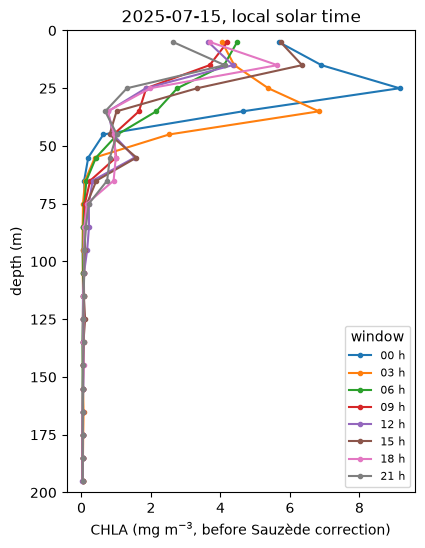

In [9]:
day = win[win["profile_id"].str.contains("20250715T")]
mid = np.arange(5, 200, 10)
fig, ax = plt.subplots(figsize=(4.5, 6))
for _, r in day.iterrows():
    ax.plot(r[b.CHLA_COLS].to_numpy(float), mid, marker=".",
            label=r["profile_id"][-2:] + " h")
ax.set_ylim(200, 0)
ax.set_xlabel("CHLA (mg m$^{-3}$, before Sauzède correction)")
ax.set_ylabel("depth (m)")
ax.set_title("2025-07-15, local solar time")
ax.legend(title="window", fontsize=8);

## 5. Sauzède fluorescence:chla correction

Fluorometer chlorophyll from WET Labs ECO sensors (on Argo floats and on OOI)
reads high against HPLC chlorophyll by a factor that varies by region. Argo
`CHLA_ADJUSTED` is corrected for this; OOI chlorophyll is factory-calibrated
and uncorrected. The build divides OOI by the climatological ratio from
Sauzède (2025, SEANOE, doi:10.17882/105732), on a 1° grid, in
`datasets/chla_z/data/fluor_to_chla_lut_127630.nc`:
`CHLA = CHLA_fluorometer / chla_ratio`. A site with no value keeps ratio 1.
The table keeps `chla_ratio`, so the raw value is `CHLA * chla_ratio`.
The ratio is very site-dependent: about 0.77 here (Oregon offshore, where the
correction *raises* CHLA) up to 2.49 in the Irminger Sea.

In [10]:
ratio = chla_scaling_factor(win["lat"].values, win["lon"].values, lut=load_lut())
win["chla_ratio"] = ratio
for c in b.CHLA_COLS:
    win[c] = win[c] / np.where(np.isnan(ratio), 1.0, ratio)
print("ratio at this site:", np.unique(ratio.round(4)))

ratio at this site: [0.7713]


## 6. Check against the released table

In [11]:
released = pd.read_parquet(b.DATA_DIR / "CHLA_ooi_profiles.parquet")
m = win.merge(released, on="profile_id", suffixes=("", "_released"))
diff = np.zeros(len(m), bool)
for c in b.CHLA_COLS:
    diff |= ~np.isclose(m[c], m[f"{c}_released"], equal_nan=True)
print(f"{len(win)} windows here, {len(m)} in the released table, "
      f"{diff.sum()} differ: {m.loc[diff, 'profile_id'].tolist()}")
assert len(m) == len(win)

249 windows here, 249 in the released table, 2 differ: ['ooi-ce04osps-sf01b-3a-flortd104_20250630T15', 'ooi-ce04osps-sf01b-3a-flortd104_20250731T15']


The windows that differ (if any) sit on the month's edges. A solar-time
window can straddle the UTC month boundary: at −125° longitude, the 15–18 h
window of 31 July runs past midnight UTC into 1 August. This notebook has
only July's samples; the build pools all months of an instrument before
windowing, so those windows get their August samples too. Every other
window should be equal.

In [12]:
assert m.loc[diff, "profile_id"].str[-11:-3].isin(["20250630", "20250731"]).all()

## Running the full build

```
cd datasets/chla_z
python build.py ooi-fetch --workers 3   # ERDDAP -> _temp_data/ooi_raw/<id>/<YYYY-MM>.csv.gz
python build.py ooi                     # -> data/CHLA_ooi_profiles.parquet
```

`ooi-fetch` asks ERDDAP for each dataset's time coverage first and requests
only months inside it; every dataset-month is saved or marked empty, so a
rerun resumes. `ooi` builds the windows per instrument
(`b.ooi_dataset_unit`), and `chla_z_tables.write_ooi_profiles()` joins them,
applies the Sauzède correction (`b.ooi_combine`) and writes the table with
its metadata. Decisions and checks: `claude/notes/chla-z-rebuild-2026-11.md`.

**For model training on this table:** the windows of one instrument-day
usually share one satellite pixel, so a train/test split must be grouped by
instrument (or at least by instrument-day).